# FIFA World Cup 2026 — Objective 2: Linear Regression

**Two related but distinct prediction tasks:**

- **2.1:** 104 games; predict `GoalDifference = Goals1 − Goals2` using exactly **eight** match-level pre-match predictors.
- **2.2:** 208 team-game records; predict `GoalsScored` using exactly **eight** team-level pre-match predictors.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from IPython.display import display
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option('display.max_columns', 30)
BASE = Path.cwd()
# If executing elsewhere, set BASE to the directory containing your two Excel files.
print('Working directory:', BASE)


Working directory: /Users/gaurav/Documents/Datascience/Data Science Assessment 3


## Data loading and validation
The spreadsheets were generated from `World_Cup_2026_clean.xlsx`, with one FIFA-confirmed missing match. The **README** worksheets detail exact provenance and missing-history assumptions. Only the eight named predictors enter each model; dates, names, IDs, and historical match counts are descriptive metadata.

In [3]:
df1 = pd.read_excel(BASE / 'Regression_2_1_104_Matches.xlsx', sheet_name='MatchRegression')
df2 = pd.read_excel(BASE / 'Regression_2_2_208_Teams.xlsx', sheet_name='TeamRegression')
F1 = ['Diff_AvgGoalsFor','Diff_AvgGoalsAgainst','Diff_AvgShots','Diff_AvgShotsOnTarget',
      'Diff_AvgxG','Diff_AvgCorners','Diff_AvgFouls','Diff_WinRate']
F2 = ['Team_AvgGoalsFor','Team_AvgxG','Team_AvgShotsOnTarget','Team_AvgCorners',
      'Opponent_AvgGoalsAgainst','Opponent_AvgxGAgainst',
      'Team_DaysSinceLastMatch','Opponent_DaysSinceLastMatch']
T1,T2='GoalDifference','GoalsScored'
assert len(df1)==104 and len(df2)==208
assert df1.MatchID.nunique()==104 and df2.groupby('MatchID').size().eq(2).all()
assert len(F1)==len(F2)==8 and df1[F1].notna().all().all() and df2[F2].notna().all().all()
assert (df1.Goals1-df1.Goals2 == df1.GoalDifference).all()
assert df1[F1].apply(pd.to_numeric,errors='coerce').notna().all().all()
assert df2[F2].apply(pd.to_numeric,errors='coerce').notna().all().all()
print('Task 2.1:',df1.shape, '| Task 2.2:',df2.shape)
print('Task 2.1 features:',F1)
print('Task 2.2 features:',F2)
display(df1.head(5));display(df2.head(5))

Task 2.1: (104, 19) | Task 2.2: (208, 17)
Task 2.1 features: ['Diff_AvgGoalsFor', 'Diff_AvgGoalsAgainst', 'Diff_AvgShots', 'Diff_AvgShotsOnTarget', 'Diff_AvgxG', 'Diff_AvgCorners', 'Diff_AvgFouls', 'Diff_WinRate']
Task 2.2 features: ['Team_AvgGoalsFor', 'Team_AvgxG', 'Team_AvgShotsOnTarget', 'Team_AvgCorners', 'Opponent_AvgGoalsAgainst', 'Opponent_AvgxGAgainst', 'Team_DaysSinceLastMatch', 'Opponent_DaysSinceLastMatch']


,MatchID,Date,Stage,Team1,Team2,Goals1,Goals2,GoalDifference,Diff_AvgGoalsFor,Diff_AvgGoalsAgainst,Diff_AvgShots,Diff_AvgShotsOnTarget,Diff_AvgxG,Diff_AvgCorners,Diff_AvgFouls,Diff_WinRate,Team1_PriorMatches,Team2_PriorMatches,Source
0,1,11/06/2026,Group Stage,Mexico,South Africa,2,0,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,User supplied cleaned file
1,2,12/06/2026,Group Stage,South Korea,Czech Republic,2,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,User supplied cleaned file
2,3,12/06/2026,Group Stage,Canada,Bosnia & Herzegovina,1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,User supplied cleaned file
3,4,13/06/2026,Group Stage,USA,Paraguay,4,1,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,User supplied cleaned file
4,5,13/06/2026,Group Stage,Qatar,Switzerland,1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,User supplied cleaned file


,MatchID,Date,Stage,Team,Opponent,GoalsScored,Team_AvgGoalsFor,Team_AvgxG,Team_AvgShotsOnTarget,Team_AvgCorners,Opponent_AvgGoalsAgainst,Opponent_AvgxGAgainst,Team_DaysSinceLastMatch,Opponent_DaysSinceLastMatch,Team_PriorMatches,Opponent_PriorMatches,Source
0,1,11/06/2026,Group Stage,Mexico,South Africa,2,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,User supplied cleaned file
1,1,11/06/2026,Group Stage,South Africa,Mexico,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,User supplied cleaned file
2,2,12/06/2026,Group Stage,South Korea,Czech Republic,2,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,User supplied cleaned file
3,2,12/06/2026,Group Stage,Czech Republic,South Korea,1,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,User supplied cleaned file
4,3,12/06/2026,Group Stage,Canada,Bosnia & Herzegovina,1,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,User supplied cleaned file


## Feature definitions (all known before kickoff)

**Model 2.1 (exactly 8):** differences between Team 1 and Team 2 in their earlier-tournament averages of (1) goals for, (2) goals against, (3) shots, (4) shots on target, (5) expected goals (xG), (6) corners, (7) fouls, and (8) win fraction.

**Model 2.2 (exactly 8):** Team's earlier-tournament averages of (1) goals, (2) xG, (3) shots on target, (4) corners; Opponent's earlier-tournament averages of (5) goals conceded and (6) xG conceded; (7) team's days since previous match and (8) opponent's days since previous match.

**Shared underlying historical measurements:** goals-for, xG, shots-on-target and corners (**4**); other explanatory variables are distinct. Past tournament scores and statistics are historical observations only; no current-match shots, xG, corners or cards are used as predictors. Missing-history zeros require cautious interpretation.

## Descriptive data exploration

MATCH-LEVEL


,count,mean,std,min,25%,50%,75%,max
Diff_AvgGoalsFor,104.0,0.066,1.334,-4.500,-0.500,0.0,0.808,6.0
Diff_AvgGoalsAgainst,104.0,-0.176,1.271,-6.000,-0.688,0.0,0.208,3.0
Diff_AvgShots,104.0,1.364,6.152,-11.000,-1.625,0.0,4.000,21.0
Diff_AvgShotsOnTarget,104.0,0.647,2.666,-6.500,-0.750,0.0,1.812,9.0
Diff_AvgxG,104.0,0.120,0.772,-1.938,-0.294,0.0,0.484,2.7
Diff_AvgCorners,104.0,0.577,2.971,-8.333,-0.525,0.0,2.000,13.0
Diff_AvgFouls,104.0,-0.321,3.335,-13.000,-1.500,0.0,1.000,8.0
Diff_WinRate,104.0,0.034,0.387,-1.000,0.000,0.0,0.000,1.0
GoalDifference,104.0,0.481,2.024,-4.000,-1.000,0.0,2.000,6.0


TEAM-LEVEL


,count,mean,std,min,25%,50%,75%,max
Team_AvgGoalsFor,208.0,1.329,1.213,0.0,0.000,1.000,2.000,7.00
Team_AvgxG,208.0,1.100,0.863,0.0,0.310,1.150,1.756,4.22
Team_AvgShotsOnTarget,208.0,3.583,2.774,0.0,1.000,3.667,6.000,12.00
Team_AvgCorners,208.0,3.591,2.949,0.0,1.000,3.500,5.036,14.00
Opponent_AvgGoalsAgainst,208.0,0.977,1.101,0.0,0.000,1.000,1.271,7.00
Opponent_AvgxGAgainst,208.0,0.855,0.755,0.0,0.211,0.788,1.315,4.22
Team_DaysSinceLastMatch,208.0,4.010,2.416,0.0,3.000,5.000,6.000,8.00
Opponent_DaysSinceLastMatch,208.0,4.010,2.416,0.0,3.000,5.000,6.000,8.00
GoalsScored,208.0,1.481,1.393,0.0,0.000,1.000,2.000,7.00


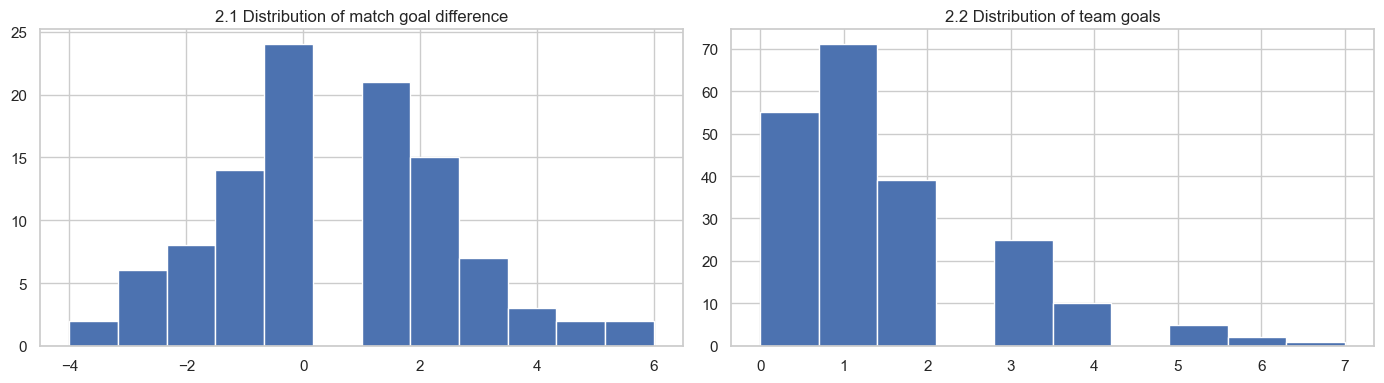

In [4]:
print('MATCH-LEVEL')
display(df1[F1+[T1]].describe().T.round(3))
print('TEAM-LEVEL')
display(df2[F2+[T2]].describe().T.round(3))
fig,ax=plt.subplots(1,2,figsize=(14,4))
ax[0].hist(df1[T1],bins=12);ax[0].set_title('2.1 Distribution of match goal difference')
ax[1].hist(df2[T2],bins=10);ax[1].set_title('2.2 Distribution of team goals')
plt.tight_layout();plt.show()

## Correlation heatmaps (8 predictors + target)

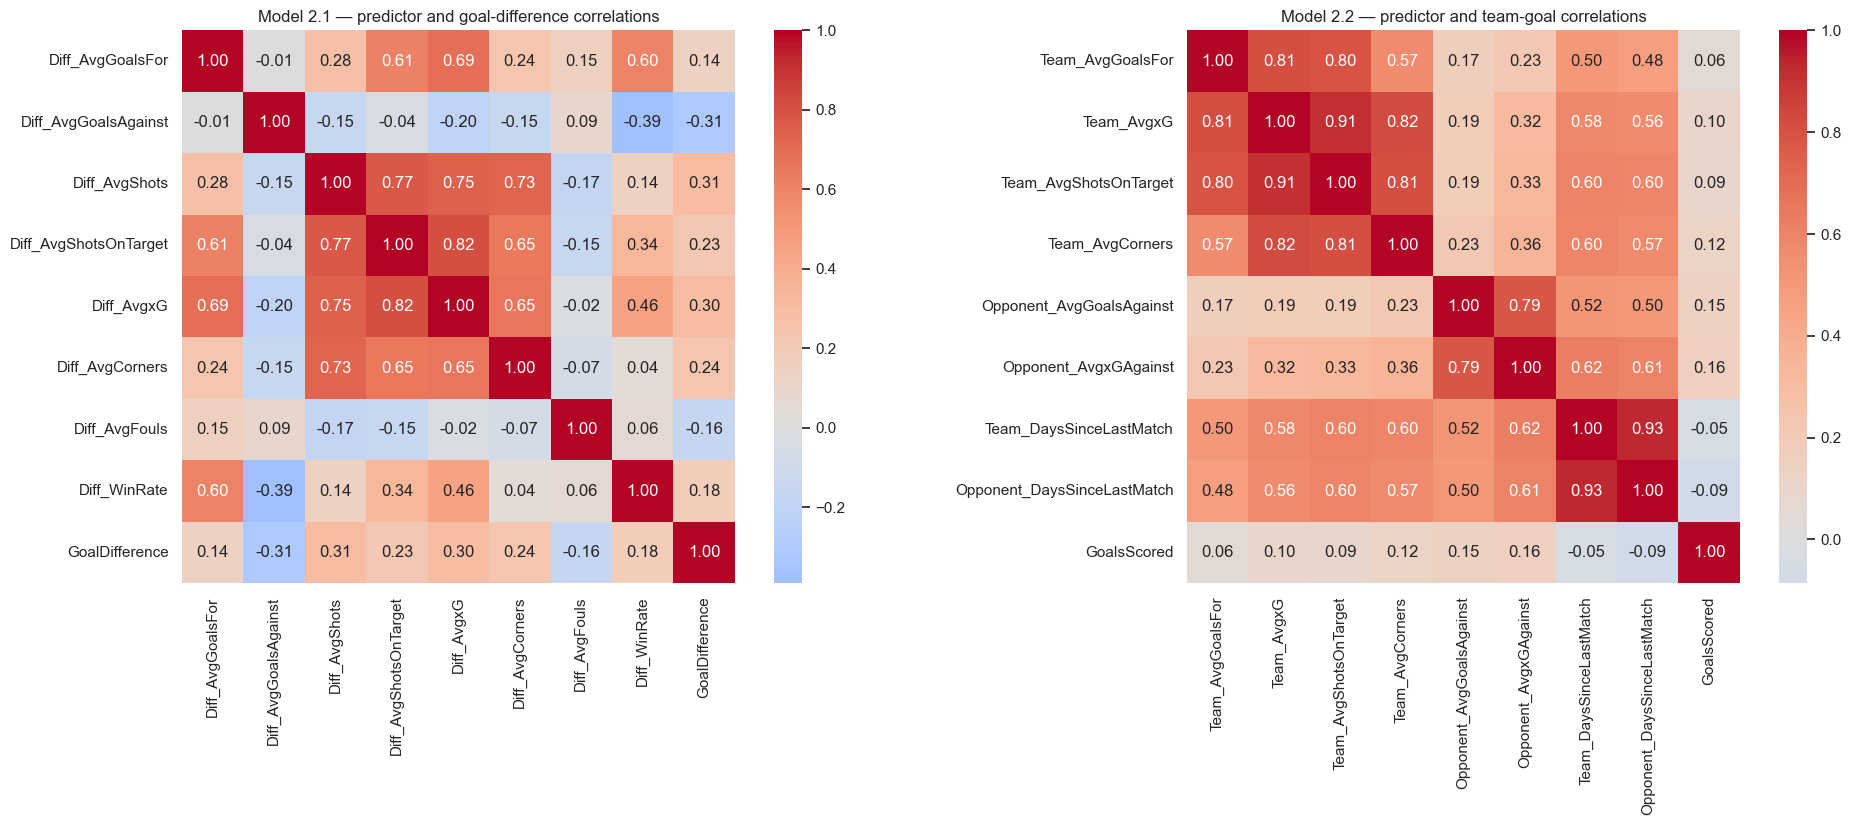

Note: correlation is descriptive, not causality; strong feature-feature correlations can cause multicollinearity.


In [5]:
fig,axes=plt.subplots(1,2,figsize=(20,8))
sns.heatmap(df1[F1+[T1]].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,ax=axes[0],square=True)
axes[0].set_title('Model 2.1 — predictor and goal-difference correlations')
sns.heatmap(df2[F2+[T2]].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,ax=axes[1],square=True)
axes[1].set_title('Model 2.2 — predictor and team-goal correlations')
plt.tight_layout();plt.show()
print('Note: correlation is descriptive, not causality; strong feature-feature correlations can cause multicollinearity.')

## Chronological train/test split
Training uses the first **80% of unique matches**; testing uses the remaining **20%**. Both team rows of a game are allocated together. This avoids splitting one result across training and testing. With a small dataset, test results have high uncertainty. All scaling occurs inside a pipeline fitted on training data only.

In [6]:
cut=int(len(df1)*0.80)
train_ids=set(df1.iloc[:cut].MatchID)
mask1=df1.MatchID.isin(train_ids)
mask2=df2.MatchID.isin(train_ids)
print('2.1:',mask1.sum(),'train /',(~mask1).sum(),'test')
print('2.2:',mask2.sum(),'train /',(~mask2).sum(),'test')
print('2.1 date range:',df1.iloc[0].Date,'to',df1.iloc[-1].Date)
assert not set(df2.loc[mask2,'MatchID']) & set(df2.loc[~mask2,'MatchID'])

2.1: 83 train / 21 test
2.2: 166 train / 42 test
2.1 date range: 11/06/2026 to 19/07/2026


## Linear regression training and baseline comparison

In [7]:
def evaluate(df,feats,target,mask,label):
    xtr=df.loc[mask,feats].astype(float); xte=df.loc[~mask,feats].astype(float)
    ytr=df.loc[mask,target].astype(float); yte=df.loc[~mask,target].astype(float)
    model=Pipeline([('scale',StandardScaler()),('linear',LinearRegression())])
    baseline=DummyRegressor(strategy='mean')
    model.fit(xtr,ytr);baseline.fit(xtr,ytr)
    predictions=model.predict(xte); basepred=baseline.predict(xte)
    rows=[]
    for name,pred in [('Mean baseline',basepred),('Linear regression',predictions)]:
        rows.append({'Task':label,'Model':name,'MAE':mean_absolute_error(yte,pred),
                     'RMSE':np.sqrt(mean_squared_error(yte,pred)),
                     'R2':r2_score(yte,pred)})
    coefs=pd.DataFrame({'Predictor':feats,'Standardized_coefficient':model.named_steps['linear'].coef_}).sort_values('Standardized_coefficient')
    return model,pd.DataFrame(rows),coefs,yte,predictions
m1,metrics1,coef1,y1,p1=evaluate(df1,F1,T1,mask1,'2.1 Goal difference')
m2,metrics2,coef2,y2,p2=evaluate(df2,F2,T2,mask2,'2.2 Team goals')
results=pd.concat([metrics1,metrics2],ignore_index=True)
display(results.round(3));display(coef1);display(coef2)
print('R² can be negative when the model performs worse than predicting the training mean.')

,Task,Model,MAE,RMSE,R2
0,2.1 Goal difference,Mean baseline,1.426,1.747,-0.302
1,2.1 Goal difference,Linear regression,1.330,1.705,-0.240
2,2.2 Team goals,Mean baseline,1.045,1.315,-0.002
3,2.2 Team goals,Linear regression,0.999,1.290,0.035


,Predictor,Standardized_coefficient
1,Diff_AvgGoalsAgainst,-0.582503
3,Diff_AvgShotsOnTarget,-0.399132
6,Diff_AvgFouls,-0.394291
7,Diff_WinRate,-0.095408
4,Diff_AvgxG,0.150235
5,Diff_AvgCorners,0.225310
2,Diff_AvgShots,0.328965
0,Diff_AvgGoalsFor,0.415102


,Predictor,Standardized_coefficient
7,Opponent_DaysSinceLastMatch,-0.906737
1,Team_AvgxG,-0.030826
0,Team_AvgGoalsFor,0.004401
2,Team_AvgShotsOnTarget,0.134059
6,Team_DaysSinceLastMatch,0.224696
4,Opponent_AvgGoalsAgainst,0.259406
5,Opponent_AvgxGAgainst,0.268107
3,Team_AvgCorners,0.322115


R² can be negative when the model performs worse than predicting the training mean.


## Graph analysis: actual vs predicted and residuals

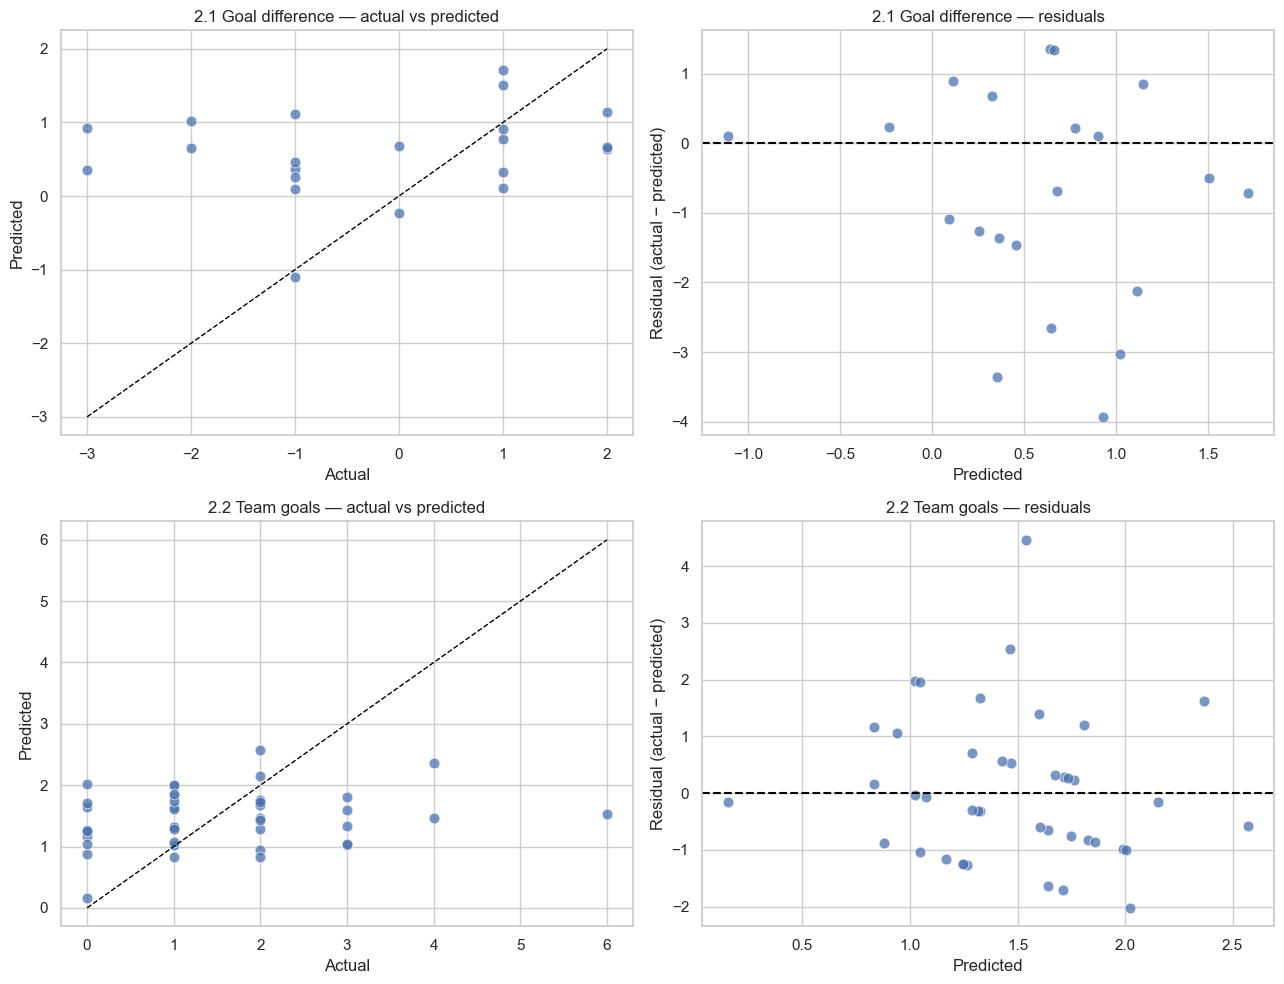

In [8]:
fig,axs=plt.subplots(2,2,figsize=(13,10))
for ix,(actual,pred,name) in enumerate([(y1,p1,'2.1 Goal difference'),(y2,p2,'2.2 Team goals')]):
    sns.scatterplot(x=np.asarray(actual),y=pred,ax=axs[ix,0],s=60,alpha=.75)
    lo=min(np.min(actual),np.min(pred)); hi=max(np.max(actual),np.max(pred))
    axs[ix,0].plot([lo,hi],[lo,hi],ls='--',color='black',lw=1)
    axs[ix,0].set(xlabel='Actual',ylabel='Predicted',title=name+' — actual vs predicted')
    residual=np.asarray(actual)-pred
    sns.scatterplot(x=pred,y=residual,ax=axs[ix,1],s=60,alpha=.75)
    axs[ix,1].axhline(0,color='black',ls='--')
    axs[ix,1].set(xlabel='Predicted',ylabel='Residual (actual − predicted)',title=name+' — residuals')
plt.tight_layout();plt.show()

## Coefficient analysis (scaled feature units)

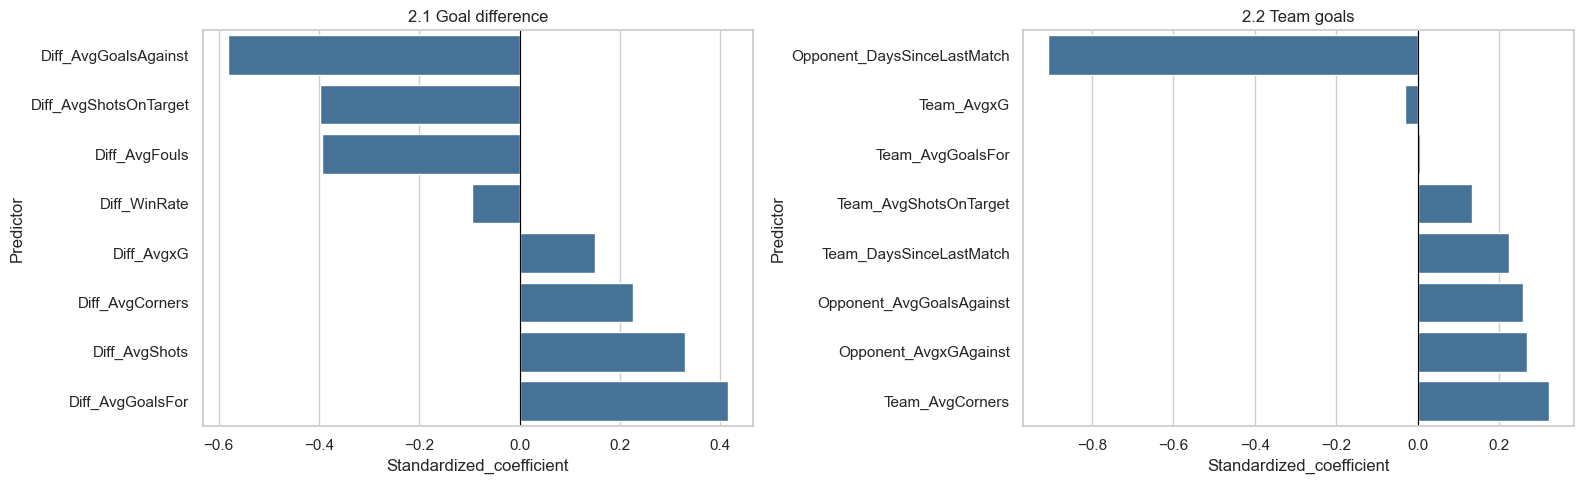

Coefficients are predictive associations conditional on the other included features, not causal effects.


In [9]:
fig,axs=plt.subplots(1,2,figsize=(16,5))
for ax,co,title in zip(axs,[coef1,coef2],['2.1 Goal difference','2.2 Team goals']):
    sns.barplot(data=co,x='Standardized_coefficient',y='Predictor',ax=ax,color='#3973A6')
    ax.axvline(0,color='black',linewidth=.8);ax.set_title(title)
plt.tight_layout();plt.show()
print('Coefficients are predictive associations conditional on the other included features, not causal effects.')

## Additional reliability checks: rolling-origin validation
With only 104 matches and historical feature quality limitations, compare the holdout metrics with 5 chronological validation folds. Fold-wise standardization and training are confined to the past. Folds are chosen by **match**, and team pairs remain together.

Rolling CV — model 2.1


,fold,MAE,RMSE,R2
0,1,1.774,2.301,-0.001
1,2,3.934,4.550,-3.298
2,3,1.747,2.175,-0.141
3,4,1.117,1.342,0.014
4,5,1.446,1.852,-0.450


Rolling CV — model 2.2


,fold,MAE,RMSE,R2
0,1,1.274,1.577,-0.000
1,2,1.851,2.368,-1.782
2,3,1.155,1.411,-0.034
3,4,0.948,1.148,-0.298
4,5,1.082,1.362,0.051


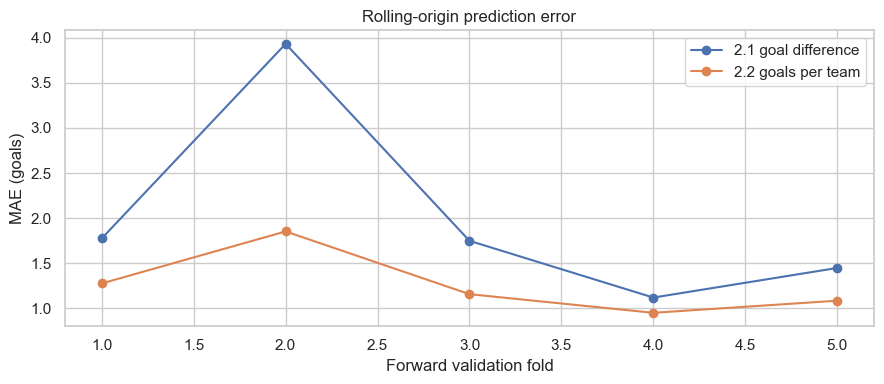

In [10]:
def rolling_cv(df, feats, target, splits=5):
    ids=df.MatchID.drop_duplicates().to_numpy()
    tscv=TimeSeriesSplit(n_splits=splits)
    out=[]
    for fold,(tr,va) in enumerate(tscv.split(ids),1):
        train=df.MatchID.isin(ids[tr]);val=df.MatchID.isin(ids[va])
        model=Pipeline([('scale',StandardScaler()),('linear',LinearRegression())])
        model.fit(df.loc[train,feats],df.loc[train,target]);pred=model.predict(df.loc[val,feats])
        obs=df.loc[val,target]
        out.append({'fold':fold,'MAE':mean_absolute_error(obs,pred),
                    'RMSE':np.sqrt(mean_squared_error(obs,pred)),'R2':r2_score(obs,pred)})
    return pd.DataFrame(out)
cv1=rolling_cv(df1,F1,T1);cv2=rolling_cv(df2,F2,T2)
print('Rolling CV — model 2.1');display(cv1.round(3));print('Rolling CV — model 2.2');display(cv2.round(3))
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(cv1.fold,cv1.MAE,marker='o',label='2.1 goal difference')
ax.plot(cv2.fold,cv2.MAE,marker='o',label='2.2 goals per team')
ax.set(xlabel='Forward validation fold',ylabel='MAE (goals)',title='Rolling-origin prediction error')
ax.legend();plt.tight_layout();plt.show()